# Лабораторная работа 3
## Расчёт зависимости коэффициента липофильности от структуры молекул с помощью линейной регрессии

### 1. Выборка и математическая постановка

Для 82 веществ использую 24 дескриптора и свободный член:

$$y_i=\beta_0+\sum_{j=1}^{24}\beta_jx_{ij}+\varepsilon_i,\qquad y_i=\log P_i.$$

Целевая переменная берётся из локального файла `lipo.csv` без повторного логарифмирования.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

LAB_DIR = Path.cwd().resolve()
if not (LAB_DIR / 'regression.py').is_file():
    LAB_DIR = LAB_DIR / 'Lab3'
if not (LAB_DIR / 'regression.py').is_file():
    raise FileNotFoundError('Рабочим каталогом должна быть папка Lab3 или корень проекта')
sys.path.insert(0, str(LAB_DIR))
from regression import FEATURES, load_data, fit_ols, metrics, design

FIG_DIR = LAB_DIR / 'figures'
RESULT_DIR = LAB_DIR / 'results'
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:.6g}')

df = load_data(LAB_DIR / 'lipo.csv')
X = df[FEATURES].to_numpy(float)
y = df.logP.to_numpy(float)
names = df.iloc[:, 0].to_numpy()
print(f'Число веществ: {len(y)}; число признаков: {X.shape[1]}')

Число веществ: 82; число признаков: 24


In [2]:
display(df.head(8))
overview = pd.DataFrame({
    'min': X.min(axis=0), 'max': X.max(axis=0),
    'mean': X.mean(axis=0), 'std': X.std(axis=0, ddof=1),
    'nonzero': (X != 0).sum(axis=0),
}, index=FEATURES)
display(overview)
print('Пропуски:', int(df.isna().sum().sum()))
print('Повторы вектора признаков:', int(df.duplicated(subset=FEATURES).sum()))
print('Диапазон logP:', y.min(), y.max())
print('Ранг [1, X]:', np.linalg.matrix_rank(design(X)), 'из', X.shape[1] + 1)
overview.to_csv(RESULT_DIR / 'data_summary.csv', encoding='utf-8-sig')

,Вещество,logP,RNH2,R2NH,R3N,ROPO3,...,AROMATIC,HBA1,HBA2,HBD,PSA,MR
0,Acetamide,-1.26,0,0,0,0,...,0,2,2,1,43.09,14.6354
1,Acetanilide,1.16,0,1,0,0,...,1,2,2,1,29.1,40.7547
2,Acetazolamide,-0.26,0,1,0,0,...,1,7,8,2,151.66,45.2161
3,Acetic acid,-0.17,0,0,0,0,...,0,2,2,1,37.3,13.4998
4,Acetohexamide,2.44,0,1,0,0,...,1,6,6,2,100.72,82.6509
5,Acetone,-0.24,0,0,0,0,...,0,1,1,0,17.07,16.735
6,Acetophenone,1.58,0,0,0,0,...,1,1,1,0,17.07,36.6365
7,Amprenavir,2.2,1,1,0,0,...,2,12,9,3,139.57,133.616


,min,max,mean,std,nonzero
RNH2,0,2,0.256098,0.466428,20
R2NH,0,2,0.353659,0.595704,24
R3N,0,2,0.146341,0.388792,11
ROPO3,0,1,0.0121951,0.110432,1
ROH,0,1,0.134146,0.342907,11
RCHO,0,1,0.0121951,0.110432,1
RCOR,0,2,0.0853659,0.322077,6
RCOOH,0,1,0.0609756,0.240758,5
RCOOR,0,1,0.0487805,0.216734,4
ROR,0,3,0.463415,0.740289,28


Пропуски: 0
Повторы вектора признаков: 4
Диапазон logP: -1.8 6.9
Ранг [1, X]: 25 из 25


### 2. Оценки коэффициентов методом наименьших квадратов

Обозначу $A=[\mathbf1,X]$. Минимизирую $(y-Ab)^T(y-Ab)$.
Из условия равенства производных нулю получаются нормальные уравнения:

$$A^TAb=A^Ty,\qquad b=(A^TA)^{-1}A^Ty.$$

В коде система решается с помощью `numpy.linalg.solve(A.T @ A, A.T @ y)`. Число параметров, включая свободный член, равно $K=25$.

In [3]:
ols = fit_ols(X, y)
table = ols.coefficients(FEATURES)
display(table[['b']])
print(f'Проверка Aᵀe ≈ 0: max|Aᵀe| = {np.max(abs(design(X).T @ ols.residuals)):.3e}')
print(f'Сумма остатков: {ols.residuals.sum():.3e}')

,b
const,0.0755758
RNH2,0.152554
R2NH,0.0970243
R3N,-0.241656
ROPO3,1.14648
ROH,0.0536147
RCHO,0.0546233
RCOR,-0.538129
RCOOH,0.902372
RCOOR,0.245787


Проверка Aᵀe ≈ 0: max|Aᵀe| = 3.098e-11
Сумма остатков: -8.971e-14


### 3. МНК-остатки

$$\widehat y=Ab,\qquad e=y-\widehat y.$$

Ниже приведены все 82 остатка в исходном порядке.
Положительный остаток означает, что наблюдаемое значение больше прогноза.

In [4]:
residuals = pd.DataFrame({'Вещество': names, 'logP': y,
                          'prediction': ols.fitted, 'residual': ols.residuals})
display(residuals)
residuals.to_csv(RESULT_DIR / 'residuals.csv', index=False, encoding='utf-8-sig')

,Вещество,logP,prediction,residual
0,Acetamide,-1.26,-0.665265,-0.594735
1,Acetanilide,1.16,1.62043,-0.460434
2,Acetazolamide,-0.26,-0.945416,0.685416
3,Acetic acid,-0.17,0.585995,-0.755995
4,Acetohexamide,2.44,1.25377,1.18623
5,Acetone,-0.24,-0.0927382,-0.147262
6,Acetophenone,1.58,1.144,0.436
7,Amprenavir,2.2,2.68558,-0.485583
8,Aniline,0.9,0.745671,0.154329
9,Anisole,2.11,1.52977,0.580233


### 4. Дисперсия МНК-ошибки и стандартная ошибка регрессии

$$\mathrm{SSE}=e^Te,\qquad s^2=\frac{e^Te}{n-K},\qquad s=\sqrt{s^2}.$$

Для этой выборки $n-K=82-25=57$.
Дополнительно квадратичная ошибка записывается в исходных единицах цели:
$\mathrm{RMSE}=\sqrt{e^Te/n}$. Она отличается от $s$ знаменателем.

### 5. Коэффициент детерминации

$$R^2=1-\frac{e^Te}{\sum_i(y_i-\overline y)^2}.$$

In [5]:
summary = {'n': len(y), 'parameters': ols.rank, 'df': ols.df,
           'SSE': ols.sse, 's2': ols.s2, 's': float(np.sqrt(ols.s2)),
           **metrics(y, ols.fitted)}
display(pd.Series(summary, name='МНК'))
(RESULT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

n                  82
parameters         25
df                 57
SSE           33.6849
s2           0.590964
s            0.768742
MSE          0.410792
RMSE          0.64093
R2           0.837989
Name: МНК, dtype: float64

216

### 6. Доверительные интервалы на основании t-статистики

$$\widehat{\operatorname{Cov}}(b)=s^2(A^TA)^{-1},\qquad
SE_j=\sqrt{\widehat{\operatorname{Cov}}(b)_{jj}},$$
$$t_j=\frac{b_j}{SE_j},\qquad
CI_{95\%,j}=b_j\pm t_{0.975,57}SE_j.$$

Принята доверительная вероятность 0.95. Для проверки $\beta_j=0$ используются
индивидуальные t-статистики. Выводы по ним условны относительно предпосылки
о независимых нормальных ошибках с одинаковой дисперсией.

t_(0.975, 57) = 2.002465


,b,SE,t,p,CI_low,CI_high
const,0.0755758,0.253696,0.297899,0.766863,-0.432441,0.583593
RNH2,0.152554,0.426144,0.357988,0.721674,-0.700783,1.00589
R2NH,0.0970243,0.380075,0.255277,0.799428,-0.664063,0.858112
R3N,-0.241656,0.534954,-0.451732,0.653177,-1.31288,0.829572
ROPO3,1.14648,1.22173,0.938409,0.351994,-1.29999,3.59295
ROH,0.0536147,0.444783,0.120541,0.904478,-0.837048,0.944277
RCHO,0.0546233,0.816646,0.0668873,0.946905,-1.58068,1.68993
RCOR,-0.538129,0.348297,-1.54503,0.127873,-1.23558,0.159323
RCOOH,0.902372,0.488188,1.84841,0.0697323,-0.0752069,1.87995
RCOOR,0.245787,0.794286,0.309444,0.758112,-1.34474,1.83632


Коэффициенты с p < 0.05 в отдельных t-тестах: HBA1, HBA2, PSA


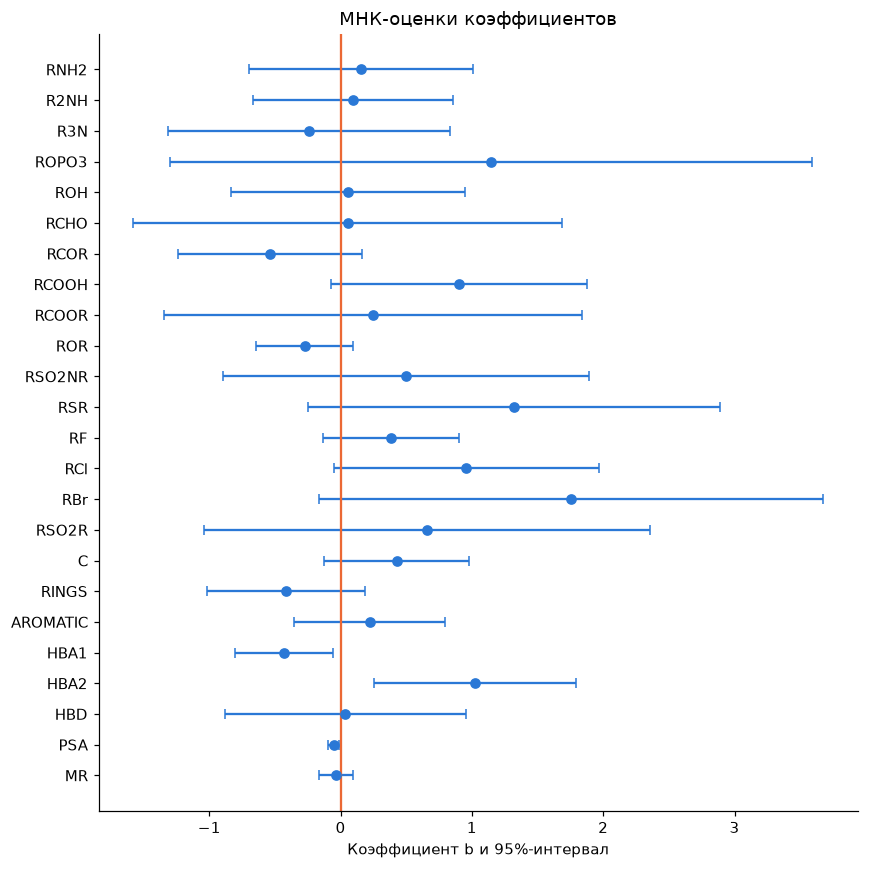

In [6]:
print(f't_(0.975, 57) = {stats.t.ppf(.975, ols.df):.6f}')
display(table)
table.to_csv(RESULT_DIR / 'coefficients.csv', index_label='feature', encoding='utf-8-sig')
significant = table.index[(table.p < .05) & (table.index != 'const')].tolist()
print('Коэффициенты с p < 0.05 в отдельных t-тестах:', ', '.join(significant))

fig, ax = plt.subplots(figsize=(8, 8))
coef = table.iloc[1:]
ax.errorbar(coef.b, np.arange(24), xerr=coef.b - coef.CI_low,
            fmt='o', color='#2a78d6', capsize=3)
ax.axvline(0, color='#eb6834')
ax.set_yticks(np.arange(24), FEATURES)
ax.invert_yaxis()
ax.set(xlabel='Коэффициент b и 95%-интервал', title='МНК-оценки коэффициентов')
fig.tight_layout()
fig.savefig(FIG_DIR / 'coefficients.png', bbox_inches='tight')
plt.show()

### 7. Анализ результатов

#### Адекватность модели

Для оценки описания выборки сопоставляю прогнозы с наблюдениями и рассматриваю остатки.
$R^2\approx0.838$: линейной моделью описывается около 84% вариации цели на этой выборке.
Эта величина характеризует подгонку; точность на новых веществах здесь не проверялась.

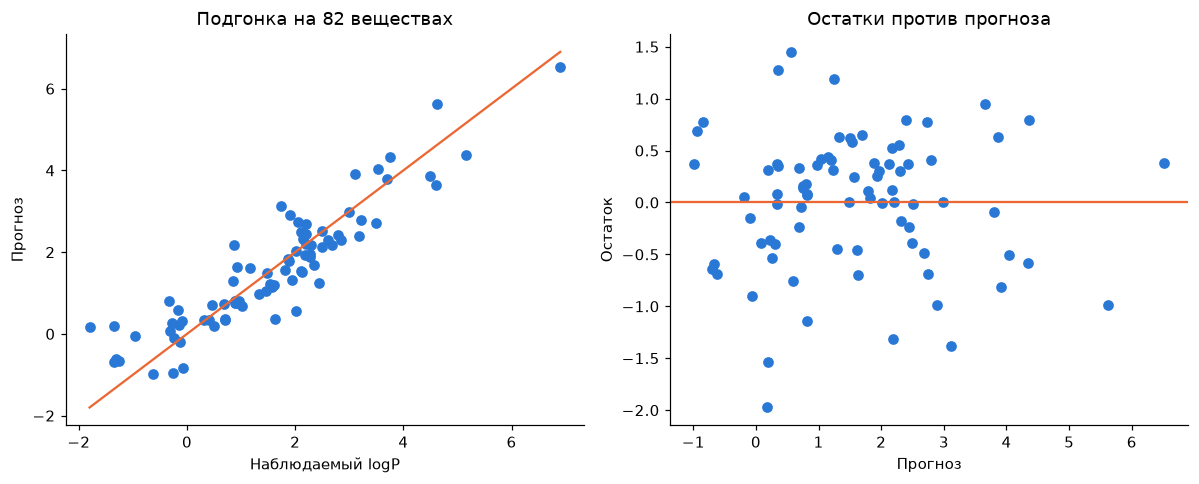

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y, ols.fitted, color='#2a78d6')
limits = [min(y.min(), ols.fitted.min()), max(y.max(), ols.fitted.max())]
axes[0].plot(limits, limits, color='#eb6834')
axes[0].set(xlabel='Наблюдаемый logP', ylabel='Прогноз', title='Подгонка на 82 веществах')
axes[1].scatter(ols.fitted, ols.residuals, color='#2a78d6')
axes[1].axhline(0, color='#eb6834')
axes[1].set(xlabel='Прогноз', ylabel='Остаток', title='Остатки против прогноза')
fig.tight_layout()
fig.savefig(FIG_DIR / 'diagnostics.png', bbox_inches='tight')
plt.show()

#### Вклад регрессоров

Коэффициент $b_j$ рассматривается как предельный эффект регрессора:
при увеличении $x_j$ на единицу прогноз меняется на $b_j$, если остальные входы фиксированы.
Единицы MR, PSA и количества групп различаются, поэтому простого сравнения $|b_j|$ недостаточно.

Для сопоставления вычисляю изменение линейного прогноза при переходе каждого признака
от его минимума к максимуму в этой выборке, при фиксированных остальных входах:

$$\Delta_j=b_j\left(\max_i x_{ij}-\min_i x_{ij}\right).$$

Это прямое следствие уравнения регрессии. Сравнение зависит от диапазона признаков;
оно не устанавливает физическую причинность.

In [8]:
effects = pd.DataFrame({'feature': FEATURES, 'b': ols.coef[1:],
                        'min': X.min(axis=0), 'max': X.max(axis=0)})
effects['prediction_change'] = effects.b * (effects['max'] - effects['min'])
effects['abs_change'] = abs(effects.prediction_change)
effects = effects.sort_values('abs_change', ascending=False)
display(effects)
effects.to_csv(RESULT_DIR / 'feature_effects.csv', index=False)
print('Наибольшее изменение прогноза по модулю:', ', '.join(effects.feature.head(5)))
print('Наименьшее изменение прогноза по модулю:', ', '.join(effects.feature.tail(3)))
print('Корреляция C и MR:', np.corrcoef(df.C, df.MR)[0, 1])

,feature,b,min,max,prediction_change,abs_change
16,C,0.427773,2,40,16.2554,16.2554
20,HBA2,1.02344,0,14,14.3282,14.3282
22,PSA,-0.0532792,0,198.03,-10.5509,10.5509
19,HBA1,-0.432086,0,18,-7.77755,7.77755
23,MR,-0.0355772,12.8898,211.956,-7.08221,7.08221
17,RINGS,-0.41448,0,7,-2.90136,2.90136
14,RBr,1.75655,0,1,1.75655,1.75655
11,RSR,1.32112,0,1,1.32112,1.32112
12,RF,0.383058,0,3,1.14918,1.14918
3,ROPO3,1.14648,0,1,1.14648,1.14648


Наибольшее изменение прогноза по модулю: C, HBA2, PSA, HBA1, MR
Наименьшее изменение прогноза по модулю: HBD, RCHO, ROH
Корреляция C и MR: 0.9849136529887675


При выбранном сравнении по диапазону наибольшие изменения прогноза связаны с C, HBA2, PSA, HBA1 и MR; наименьшие — с ROH, RCHO и HBD.

Положительный коэффициент C и отрицательный коэффициент PSA качественно согласуются
с тем, что углеродный скелет способствует сродству к органической фазе, а полярная
часть — к воде. Отрицательный MR и положительный HBA2 не следует считать самостоятельными
химическими закономерностями: коэффициенты относятся к модели с остальными фиксированными
регрессорами. Сильная связь между некоторыми признаками затрудняет такую интерпретацию.

#### Условия применимости МНК

Рассматриваются линейность, строгая экзогенность, полный столбцовый ранг, одинаковая дисперсия ошибок и отсутствие корреляции наблюдений.

- Линейность по коэффициентам задана уравнением модели. Адекватность этой формы
  для любых веществ из одного CSV не следует.
- Ранг $A$ равен 25: точной линейной зависимости столбцов нет. Сильная корреляция
  некоторых признаков при этом сохраняется.
- Нулевые $A^Te$ и сумма остатков следуют из нормальных уравнений.
  Они не доказывают строгую экзогенность истинных, ненаблюдаемых ошибок.
- По графику остатков можно описать характер подгонки, но нельзя доказать
  постоянство дисперсии и независимость измерений. Эти предпосылки по CSV не подтверждены.
- Для t-интервалов дополнительно предполагается нормальность ошибок.
  Здесь это предположение принято условно, без отдельного теста нормальности.

#### Сопоставление с работой [2] из задания

Сравниваю итоговые статистики с таблицей 2 работы Lopez, Pinheiro, Zamora (2021),
указанной в задании: [DOI 10.1007/s10822-021-00409-2](https://doi.org/10.1007/s10822-021-00409-2).
Для MLR-1 берутся первые 19 признаков, для MLR-2 — первые 22, для MLR-3 — все 24.
Это сравнение по R², квадратичной ошибке и стандартной ошибке регрессии;
покомпонентное сопоставление коэффициентов статьи не выполняется.

In [9]:
published = [(19, .79, .72, .83), (22, .82, .68, .80), (24, .84, .64, .77)]
comparison = []
for i, (p, r2, rmse, standard_error) in enumerate(published, 1):
    result = fit_ols(X[:, :p], y)
    comparison.append({'model': f'MLR-{i}', 'source': 'расчёт', 'R2': result.r2,
                       'RMSE': metrics(y, result.fitted)['RMSE'], 's': np.sqrt(result.s2)})
    comparison.append({'model': f'MLR-{i}', 'source': 'статья, табл. 2',
                       'R2': r2, 'RMSE': rmse, 's': standard_error})
comparison = pd.DataFrame(comparison)
display(comparison)
comparison.to_csv(RESULT_DIR / 'article_comparison.csv', index=False, encoding='utf-8-sig')

,model,source,R2,RMSE,s
0,MLR-1,расчёт,0.794316,0.72217,0.830521
1,MLR-1,"статья, табл. 2",0.79,0.72,0.83
2,MLR-2,расчёт,0.819273,0.676942,0.798054
3,MLR-2,"статья, табл. 2",0.82,0.68,0.8
4,MLR-3,расчёт,0.837989,0.64093,0.768742
5,MLR-3,"статья, табл. 2",0.84,0.64,0.77


### Итоги

1. Найдены 25 МНК-оценок и 82 остатка по локальному файлу `lipo.csv`.
2. Получены $s^2=0.590964$, $s=0.768742$, $R^2=0.837989$.
3. Для всех коэффициентов рассчитаны t-статистики и индивидуальные 95%-интервалы.
4. Модель описывает большую часть вариации на исходной выборке. Независимость,
   экзогенность и постоянство дисперсии ошибок по этой таблице не установлены.
5. Итоговые статистики трёх линейных моделей совпадают с таблицей 2 статьи после округления.

Проверка из папки `Lab3`: `python -m unittest discover -s tests -v`.